# Forward-quarter warning-budget validation

Select a separate threshold for each model using **only earlier out-of-fold development quarters**, then freeze it for the next quarter. Q1 2024 initializes calibration; Q2 2024 through Q2 2025 are evaluated. The two independent policies target 20 false-warning episodes/day or 4 wrong-alert hours/day across the corridor. Actual next-quarter burden may exceed the calibration budget.

This evaluates threshold transfer between quarterly model fits, conditional on the existing 29-feature development workflow. It is not a final holdout estimate or an independent repeat of feature/model selection. No models are retrained and July?December 2025 stays untouched.


## Results from the saved forward test

The five evaluated quarters contain **7,587 onsets**. With thresholds calibrated to 4 wrong-alert hours/day, early detection was **53.2% for Transformer, 52.7% for boosted trees, and 43.5% for Random Forest**. Realized mean burdens were 3.19, 3.31 and 3.49 hours/day, respectively. Transformer breached this budget in one of five quarters; the other two models did not. The 0.5 percentage-point detection difference between Transformer and boosted trees is small and is not evidence of statistical significance.

With the separate 20 false-episode/day calibration policy, detection was 46.3%, 39.9% and 23.0%, respectively, at realized 17.32, 16.90 and 17.80 false episodes/day. Transformer exceeded the episode budget in one quarter. Equal calibration budgets do not guarantee equal realized costs.

The timetable baseline caught 48.2% under the episode policy, but generated **6.78 wrong-alert hours/day**, illustrating why episode counts alone can hide prolonged warnings. Under the duration policy its detection fell to 27.4%. Rare-onset results and missing-context counts are available in the recurrence tables. These are development results; the final holdout remains untouched.


In [1]:
from pathlib import Path
import sys, json, hashlib
from datetime import datetime
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
ROOT = next(p for p in (Path.cwd().resolve(), *Path.cwd().resolve().parents)
            if (p / 'notebooks/safeflow_features.py').is_file())
sys.path[:0] = [str(ROOT), str(ROOT / 'notebooks')]
import safeflow_features as sf
from src.analysis.early_warning_errors import align_predictions, forward_budget_validation, warning_leads
EPISODE_BUDGET, HOURS_BUDGET = 20, 4
# Reuse a completed, provenance-checked all-model analysis; override explicitly if needed.
SOURCE_RUN = None
candidates = sorted((ROOT / 'results/error_analysis_models').glob('*/manifest.json'), reverse=True)
if SOURCE_RUN is None:
    SOURCE_RUN = next(p.parent for p in candidates if len(json.loads(p.read_text())['input_provenance']) == 3)
manifest = json.loads((SOURCE_RUN / 'manifest.json').read_text())
assert not manifest['holdout_used']
assert hashlib.sha256((ROOT / 'notebooks/safeflow_features.py').read_bytes()).hexdigest() == manifest['shared_code_sha256']
cache = ROOT / 'results/error_analysis_models/cache' / ('validation_context_' + manifest['context_signature'][:16] + '.parquet')
if not cache.exists():
    raise FileNotFoundError('Run analysis/error_analysis_models.ipynb first to build its development context cache.')
reference = pd.read_parquet(cache).sort_values(['station','timestamp']).reset_index(drop=True)
assert reference.timestamp.max() < pd.Timestamp('2025-07-01')
OUT = ROOT / 'results/forward_warning_budget_validation' / datetime.now().strftime('%Y%m%d_%H%M%S_%f')
OUT.mkdir(parents=True)
print('Source analysis:', SOURCE_RUN)
print('Validation rows:', len(reference), '| output:', OUT)


Source analysis: C:\Erdos\Project\safeflow\results\error_analysis_models\20261104_095913_315957
Validation rows: 2898000 | output: C:\Erdos\Project\safeflow\results\forward_warning_budget_validation\20261104_102956_926783


In [2]:
probabilities = {'Timetable': reference.typical_congestion_30.fillna(0).to_numpy()}
for model, provenance in manifest['input_provenance'].items():
    files = []
    for saved, expected_hash in zip(provenance['files'], provenance['sha256'], strict=True):
        # Export paths are portable across machines: retain the repository-relative src/... suffix.
        normalized = saved.replace('\\', '/')
        relative = 'src/' + normalized.split('/src/', 1)[1]
        path = ROOT / relative
        assert hashlib.sha256(path.read_bytes()).hexdigest() == expected_hash, path
        files.append(pd.read_parquet(path))
    probabilities[model] = align_predictions(reference, pd.concat(files, ignore_index=True), provenance['probability_column'])
    print('Aligned and verified:', model, flush=True)


Aligned and verified: Random Forest
Aligned and verified: Transformer
Aligned and verified: Boosted trees (29)


## Calibrate on the past, evaluate the next quarter

Threshold selection maximizes the fraction of onsets warned at least 15 minutes early, subject to the calibration cost. False-warning episodes are not monotone in the threshold, so we search exact score breakpoints. Prior-quarter predictions come from earlier quarterly fits; their score calibration can differ from the next fit. Budget breaches reveal that transfer risk rather than being corrected using future outcomes.


In [3]:
tables, group_rows = [], []
for model, p in probabilities.items():
    print('Forward validation:', model, flush=True)
    result = forward_budget_validation(reference, p, EPISODE_BUDGET, HOURS_BUDGET)
    result['model'] = model
    tables.append(result)
    for row in result.itertuples():
        mask = reference.fold.eq(row.fold).to_numpy()
        test = reference.loc[mask].copy()
        scores = p[mask]
        shared = sf.alert_metrics(test, scores, row.threshold)
        assert np.isclose(shared['caught ≥15 min'], row.caught_15min)
        assert np.isclose(shared['false alarms / day'], row.false_episodes_per_day)
        assert np.isclose(shared['wrong-alert hours / day'], row.wrong_alert_hours_per_day)
        onsets = test.loc[test.onset, ['station','timestamp']].copy()
        index = pd.MultiIndex.from_arrays([onsets.station, onsets.timestamp-pd.Timedelta(minutes=15)])
        recurrence = test.set_index(['station','timestamp']).typical_congestion_30.reindex(index).to_numpy()
        groups = np.where(~np.isfinite(recurrence), 'unknown', np.where(recurrence < .1, 'non-recurrent', np.where(recurrence < .4,'occasional','recurrent')))
        lead = warning_leads(test, scores, onsets, row.threshold)
        for group in ['non-recurrent','occasional','recurrent','unknown']:
            use = groups == group
            group_rows.append(dict(model=model,fold=row.fold,budget_type=row.budget_type,group=group,onsets=int(use.sum()),caught=int(((lead>=15)&use).sum())))
results = pd.concat(tables, ignore_index=True)
group_results = pd.DataFrame(group_rows)
summary_rows = []
for (model, policy), frame in results.groupby(['model','budget_type'], sort=False):
    days = frame.days.sum()
    summary_rows.append(dict(model=model, policy=policy, onsets=int(frame.onsets.sum()),
        catch_15min=frame.caught_count.sum()/frame.onsets.sum(),
        false_episodes_per_day=np.average(frame.false_episodes_per_day, weights=frame.days),
        wrong_alert_hours_per_day=np.average(frame.wrong_alert_hours_per_day, weights=frame.days),
        quarters_over_budget=int(frame.budget_exceeded.sum()), evaluated_quarters=len(frame)))
summary = pd.DataFrame(summary_rows)
group_summary = group_results.groupby(['model','budget_type','group'],as_index=False)[['onsets','caught']].sum()
group_summary['catch_15min'] = group_summary.caught/group_summary.onsets.replace(0,np.nan)
display(summary.round(4))
for name, table in [('quarterly_policies',results),('summary',summary),('recurrence_by_quarter',group_results),('recurrence_summary',group_summary)]:
    table.to_csv(OUT / (name + '.csv'),index=False)


Forward validation: Timetable
Forward validation: Random Forest
Forward validation: Transformer
Forward validation: Boosted trees (29)


,model,policy,onsets,catch_15min,false_episodes_per_day,wrong_alert_hours_per_day,quarters_over_budget,evaluated_quarters
0,Timetable,episodes,7587,0.4816,14.9457,6.7801,0,5
1,Timetable,duration,7587,0.2738,6.6837,2.9092,1,5
2,Random Forest,episodes,7587,0.2297,17.7987,1.9886,0,5
3,Random Forest,duration,7587,0.4355,26.0927,3.4864,0,5
4,Transformer,episodes,7587,0.4626,17.3163,2.4276,1,5
5,Transformer,duration,7587,0.5321,21.1246,3.1941,1,5
6,Boosted trees (29),episodes,7587,0.3994,16.8978,2.1736,0,5
7,Boosted trees (29),duration,7587,0.5271,23.2077,3.3096,0,5


## Detection and realized warning burden

Each point below uses a threshold selected before its evaluation quarter. The dashed line is the calibration budget, not a constraint imposed on evaluation. Compare early detection together with actual burden: these are equal **intended** budgets, not guaranteed identical realized costs. Aggregated detection weights onsets; aggregated cost weights evaluated days.


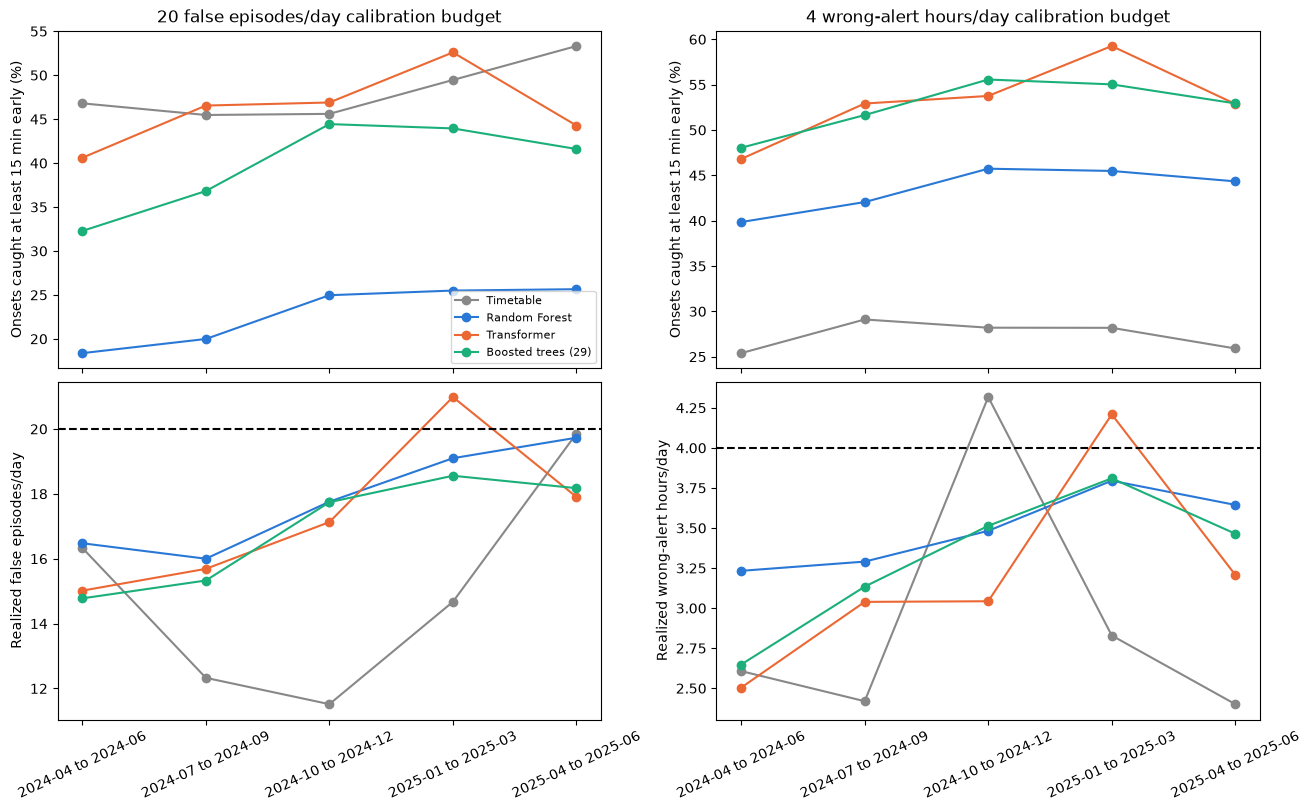

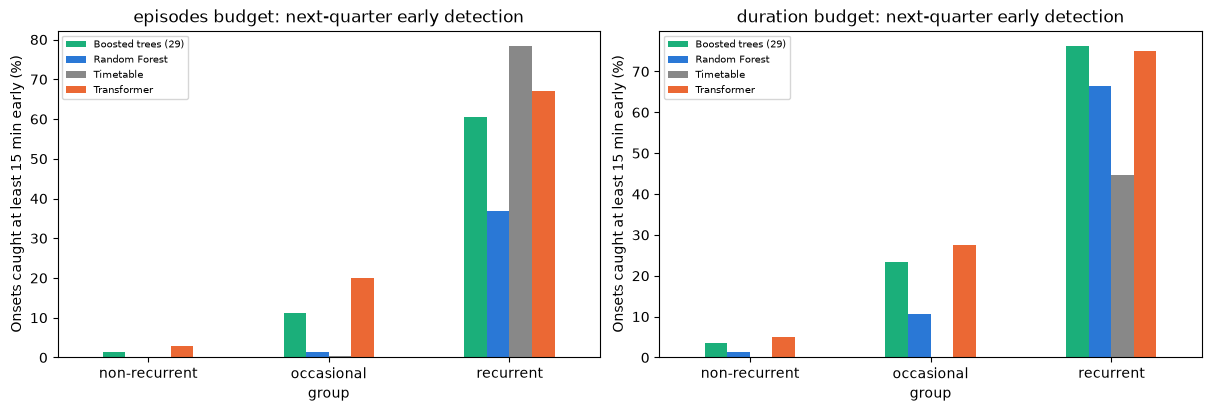

In [4]:
colors = dict(zip(probabilities, ['#888888','#2a78d6','#eb6834','#1baf7a']))
fig, axes = plt.subplots(2,2,figsize=(13,8),sharex=True,layout='constrained')
for col, (policy, cost, budget) in enumerate([('episodes','false_episodes_per_day',EPISODE_BUDGET),('duration','wrong_alert_hours_per_day',HOURS_BUDGET)]):
    for model in probabilities:
        f = results.loc[results.model.eq(model)&results.budget_type.eq(policy)]
        axes[0,col].plot(f.fold, 100*f.caught_15min, marker='o',label=model,color=colors[model])
        axes[1,col].plot(f.fold, f[cost], marker='o',color=colors[model])
    axes[0,col].set_title(f'{budget} '+('false episodes/day' if policy=='episodes' else 'wrong-alert hours/day')+' calibration budget')
    axes[0,col].set_ylabel('Onsets caught at least 15 min early (%)')
    axes[1,col].axhline(budget,color='black',linestyle='--',label='Calibration budget')
    axes[1,col].set_ylabel('Realized '+('false episodes/day' if policy=='episodes' else 'wrong-alert hours/day'))
    axes[1,col].tick_params(axis='x',rotation=25)
axes[0,0].legend(fontsize=8)
fig.savefig(OUT / 'forward_detection_and_burden.png',dpi=160)
plt.show()
fig, axes = plt.subplots(1,2,figsize=(12,4),layout='constrained')
for ax, policy in zip(axes,['episodes','duration']):
    data = group_summary.loc[group_summary.budget_type.eq(policy)&group_summary.group.ne('unknown')]
    data.pivot(index='group',columns='model',values='catch_15min').reindex(['non-recurrent','occasional','recurrent']).mul(100).plot.bar(ax=ax,color=[colors[c] for c in data.pivot(index='group',columns='model',values='catch_15min').columns])
    ax.set_title(policy+' budget: next-quarter early detection')
    ax.set_ylabel('Onsets caught at least 15 min early (%)')
    ax.tick_params(axis='x',rotation=0)
    ax.legend(fontsize=7)
fig.savefig(OUT / 'forward_recurrence.png',dpi=160)
plt.show()


## Interpretation and limits

Read the table and plots together: higher catch at a higher realized cost does not establish superiority at exactly equal burden. Quarter-to-quarter changes can reflect seasonality, a new model fit, or calibration drift. Rare-jam performance is based on the training-only usual congestion rate 15 minutes before each onset; events with missing context are reported separately.

This is a forward threshold test over development predictions. Budgets and model/features have already been discussed using these development quarters, so it remains developmental evidence. Freeze the final policy before accessing the final holdout. Thresholds should not be adjusted using the evaluated quarter merely to force a favorable budget comparison.


In [5]:
assert len(results) == 4 * 2 * 5
assert (pd.to_datetime(results.calibration_end) < pd.to_datetime(results.test_start)).all()
assert group_results.groupby(['model','budget_type','fold']).onsets.sum().to_numpy().sum() == results.onsets.sum()
output_manifest = dict(source_analysis=str(SOURCE_RUN.relative_to(ROOT)), context_signature=manifest['context_signature'],
    input_provenance=manifest['input_provenance'], shared_code_sha256=manifest['shared_code_sha256'],
    holdout_used=False, retrained=False, calibration='expanding earlier OOF quarters only',
    evaluation_quarters=sorted(results.fold.unique()), episode_budget=EPISODE_BUDGET,hours_budget=HOURS_BUDGET,
    scorer_checks='all 40 policies match shared alert_metrics', min_lead_minutes=15)
(OUT / 'manifest.json').write_text(json.dumps(output_manifest,indent=2),encoding='utf-8')
print('Saved tables, plots and provenance:', OUT)


Saved tables, plots and provenance: C:\Erdos\Project\safeflow\results\forward_warning_budget_validation\20261104_102956_926783
